In [20]:
import tensorflow as tf
from tensorflow.keras import utils
import numpy as np
import matplotlib.pyplot as plt

In [67]:
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import InputLayer

# 資料預處理

In [4]:
from tensorflow.keras.datasets import fashion_mnist

(x_train_image, y_train_label), \
(x_test_image, y_test_label) = fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [6]:
x_Train = x_train_image.reshape(60000, 784).astype('float32')
x_Test = x_test_image.reshape(10000, 784).astype('float32')

In [7]:
x_Train_normalize = x_Train / 255
x_Test_normalize = x_Test / 255

In [8]:
y_Train_OneHot = utils.to_categorical(y_train_label)
y_Test_OneHot = utils.to_categorical(y_test_label)

# 顯示訓練圖片與真實標籤

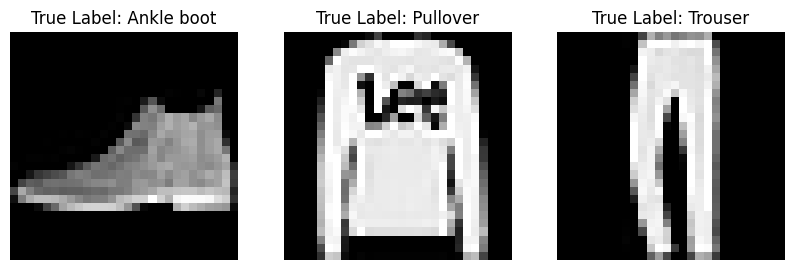

In [21]:
class_names = [
    "T-shirt/top", "Trouser", "Pullover",
    "Dress", "Coat", "Sandal",
    "Shirt", "Sneaker", "Bag", "Ankle boot"
]

plt.figure(figsize=(10, 4))
for i in range(3):
    plt.subplot(1, 3, i+1)
    plt.imshow(x_test_image[i], cmap='gray')
    plt.title("True Label: " + class_names[y_test_label[i]])
    plt.axis('off')

plt.show()

In [55]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import InputLayer, Dense, Dropout

model = Sequential()

# 輸入層

In [57]:
model.add(InputLayer(shape=(784,)))
model.add(Dropout(0.2))

# 第一隱藏層

In [58]:
model.add(Dense(512, kernel_initializer='he_normal', activation='relu'))
model.add(Dropout(0.4))

# 第二隱藏層

In [61]:
model.add(Dense(256, kernel_initializer='he_normal', activation='softmax'))
model.add(Dropout(0.2))

# 第三隱藏層

In [62]:
model.add(Dense(128, kernel_initializer='he_normal', activation='relu'))
model.add(Dropout(0.2))

# 輸出層

In [63]:
model.add(Dense(units=10, kernel_initializer='he_normal', activation='softmax'))

In [64]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dropout_7 (Dropout)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 10)             │         1,290 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 256)            │         2,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 505,876 (1.93 MB)

 Trainable params: 505,876 (1.93 MB)

 Non-trainable params: 0 (0.00 B)

# 訓練神經網路模型

In [68]:
model.compile(
    loss='categorical_crossentropy',
    optimizer=Adam(0.000239),
    #optimizer='adam',
    metrics=['accuracy'])

In [70]:
train_history = model.fit(
    x_Train_normalize, y_Train_OneHot,
    validation_split=0.2,
    epochs=200, #訓練*次
    batch_size=256,
    verbose=2)

Epoch 1/200
188/188 - 7s - 38ms/step - accuracy: 0.0968 - loss: 2.3027 - val_accuracy: 0.0957 - val_loss: 2.3025
Epoch 2/200
188/188 - 6s - 33ms/step - accuracy: 0.1094 - loss: 2.3021 - val_accuracy: 0.1934 - val_loss: 2.3013
Epoch 3/200
188/188 - 9s - 48ms/step - accuracy: 0.1485 - loss: 2.2979 - val_accuracy: 0.1922 - val_loss: 2.2902
Epoch 4/200
188/188 - 6s - 34ms/step - accuracy: 0.1792 - loss: 2.2579 - val_accuracy: 0.1913 - val_loss: 2.1915
Epoch 5/200
188/188 - 5s - 25ms/step - accuracy: 0.1796 - loss: 2.0805 - val_accuracy: 0.1922 - val_loss: 1.9151
Epoch 6/200
188/188 - 6s - 33ms/step - accuracy: 0.1778 - loss: 1.8985 - val_accuracy: 0.1988 - val_loss: 1.7636
Epoch 7/200
188/188 - 9s - 50ms/step - accuracy: 0.1769 - loss: 1.8382 - val_accuracy: 0.1987 - val_loss: 1.7123
Epoch 8/200
188/188 - 7s - 38ms/step - accuracy: 0.1819 - loss: 1.8206 - val_accuracy: 0.1947 - val_loss: 1.6997
Epoch 9/200
188/188 - 5s - 26ms/step - accuracy: 0.1798 - loss: 1.8140 - val_accuracy: 0.2090 - 

# 顯示 loss & accuracy 折線圖

In [72]:
def show_train_history(train_history, train, validation):
    plt.plot(train_history.history[train])
    plt.plot(train_history.history[validation])
    plt.title('Train History')
    plt.ylabel(train)
    plt.xlabel('Epoch')
    plt.legend(['train', 'validation'], loc='upper left')
    plt.show()

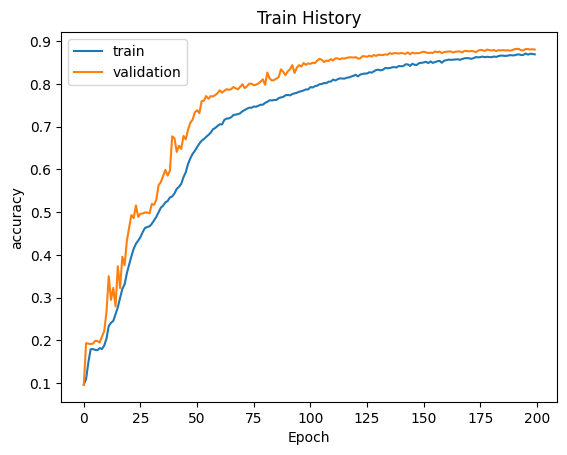

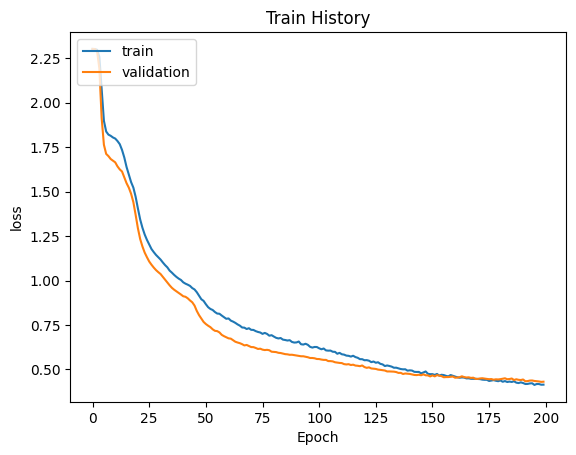

In [73]:
show_train_history(train_history, 'accuracy', 'val_accuracy')
show_train_history(train_history, 'loss', 'val_loss')

# 評估準確率

In [74]:
scores = model.evaluate(x_Train_normalize, y_Train_OneHot)
print(f"accuracy = {scores[1]}")

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9036 - loss: 0.3265
accuracy = 0.9036333560943604


# 預測

In [76]:
predictions = model.predict(x_Train_normalize)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step


In [77]:
predicted_classes = np.argmax(predictions, axis=1)

In [78]:
predicted_classes

array([9, 0, 0, ..., 3, 0, 5])

# 顯示圖片與標籤名稱2

In [79]:
import matplotlib.pyplot as plt

def plot_images_labels_prediction(images, true_labels, pred_labels, label_names, idx=0, num=10):
  plt.figure(figsize=(6, 7))
  if num > 25: num = 25
  for i in range(num):
    plt.subplot(5, 5, i + 1)
    plt.imshow(images[idx + i], cmap='gray')

    true_name = label_names[true_labels[idx + i]]
    pred_name = label_names[pred_labels[idx + i]]

    plt.title(f'True: {true_name}\nPred: {pred_name}', fontsize=10)
    plt.axis('off')

  plt.tight_layout()
  plt.show()


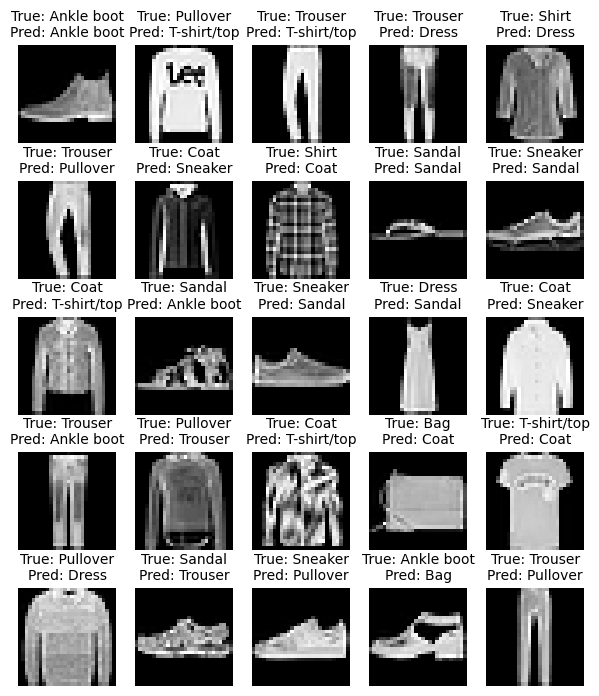

In [84]:
plot_images_labels_prediction(x_test_image, y_test_label, predicted_classes, class_names, idx=0, num=25)

# 混淆矩陣

In [94]:
prediction = model.predict(x_Test_normalize)
predicted_classes = np.argmax(prediction, axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [95]:
import pandas as pd

pd.crosstab(
    y_test_label,
    predicted_classes,
    rownames=['class_names'],
    colnames=['predict']
)

predict,0,1,2,3,4,5,6,7,8,9
class_names,,,,,,,,,,
0,891,2,3,28,8,0,65,0,3,0
1,1,968,0,25,1,0,4,0,1,0
2,17,0,769,8,162,0,43,0,1,0
3,50,4,6,886,23,0,30,0,1,0
4,5,0,101,22,783,0,89,0,0,0
5,0,0,0,0,0,953,0,27,1,19
6,233,0,66,24,132,0,542,0,3,0
7,0,0,0,0,0,6,0,973,0,21
8,2,0,7,2,6,0,3,5,975,0
